In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Chapitre 2: Comprendre le machine learning: la regression polynomiale

Considérons une variable expliquée $y$ et $X$ une variable explicative. Souvent la regression linéaire ne permet pas d'expliquer la relation entre les deux variables, dans ce cas on passe à une autre relation, qui peut être polynomiale. Et c'est ce qu'on vera dans cette partie.

In [2]:
data = pd.read_csv('2_regression_polynomiale.csv')
data.head()

,x,y
0,-4.096,22.800
1,3.970,0.496
2,-4.710,24.010
3,-2.592,15.185
4,-3.570,13.208


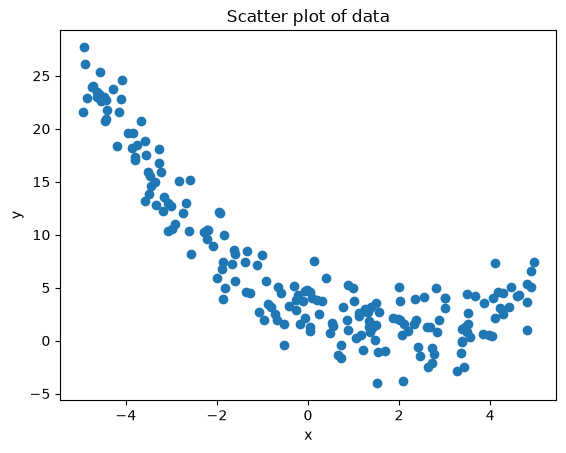

In [3]:
plt.scatter(data['x'], data['y'])
plt.xlabel('x')
plt.ylabel('y')
plt.title('Scatter plot of data')
plt.show()

Le but est d'approximer le jeu de données avec un droite parabolique dont l'équation est donnée par 

$$f(x) = \beta_{0} + \beta_{1}x + \beta_{2}x^{2} $$

Et le but est de savoir quelles sont les valeurs des différents paramètres que sont $\beta_{0}, \beta_{1} \text{ et } \beta{2}$

Comme dans la regression linéaire on va définir notre modèle:

$$y_{i} = \beta_{0} + \beta_{1}x_{i} + \beta_{2}x_{i}^{2} + \epsilon_{i}$$

$$\sum_{i=1}^{n}\epsilon_{i}^{2} = \sum_{i=1}^{n}(\beta_{0} + \beta_{1}x_{i} + \beta_{2}x_{i}^{2} - y_{i})^{2}$$


$$\frac{\partial \sum_{i=1}^{n}\epsilon_{i}^{2} }{\partial \beta_{0}} = 0 ; \frac{\partial \sum_{i=1}^{n}\epsilon_{i}^{2} }{\partial \beta_{1}} = 0; \frac{\partial \sum_{i=1}^{n}\epsilon_{i}^{2} }{\partial \beta_{2}} = 0$$

$$N\beta_{0} + \beta_{1}\sum_{i=1}x_{i} + \beta_{2} \sum_{i=1}x_{i}^{2} = \sum_{i=1}^{N}y \quad (1)$$

$$\beta_{0}\sum_{i=1}x_{i} + \beta_{1}\sum_{i=1}{x_{i}^{2}} + \beta_{2}\sum_{i=1}x_{i}^{3} = \sum_{i=1}x_{i}y_{i} \quad (2)$$

$$\beta_{0}\sum_{i=1}x_{i}^{2} + \beta_{1}\sum_{i=1}{x_{i}^{3}} + \beta_{2}\sum_{i=1}x_{i}^{4} = \sum_{i=1}x_{i}^{2}y_{i} \quad (2)$$

In [4]:
data['x_squared'] = data['x'] ** 2
data['x_cubed'] = data['x'] ** 3
data['x_quartic'] = data['x'] ** 4
data['xy'] = data['x'] * data['y']
data['x_squared_y'] = data['x_squared'] * data['y']

data.head(10)

,x,y,x_squared,x_cubed,x_quartic,xy,x_squared_y
0,-4.096,22.800,16.777216,-68.719477,281.474977,-93.388800,382.520525
1,3.970,0.496,15.760900,62.570773,248.405969,1.969120,7.817406
2,-4.710,24.010,22.184100,-104.487111,492.134293,-113.087100,532.640241
3,-2.592,15.185,6.718464,-17.414259,45.137759,-39.359520,102.019876
4,-3.570,13.208,12.744900,-45.499293,162.432476,-47.152560,168.334639
5,2.768,-1.267,7.661824,21.207929,58.703547,-3.507056,-9.707531
6,-3.018,12.743,9.108324,-27.488922,82.961566,-38.458374,116.067373
7,4.106,2.177,16.859236,69.224023,284.233839,8.938762,36.702557
8,1.563,2.721,2.442969,3.818361,5.968098,4.252923,6.647319
9,-4.638,23.517,21.511044,-99.768222,462.725014,-109.071846,505.875222


In [5]:
# on va calculer les différentes sommes 

sum_x = data['x'].sum()
sum_y = data['y'].sum()
sum_x_squared = data['x_squared'].sum()
sum_x_cubed = data['x_cubed'].sum()
sum_x_quartic = data['x_quartic'].sum()
sum_xy = data['xy'].sum()
sum_x_quadratic_y = data['x_squared_y'].sum()

sum_x, sum_y, sum_x_squared, sum_x_cubed, sum_x_quartic, sum_xy, sum_x_quadratic_y

(np.float64(-5.887999999999995),
 np.float64(1417.834),
 np.float64(1649.9240559999998),
 np.float64(-424.58392026200005),
 np.float64(24658.532528193624),
 np.float64(-3610.658894),
 np.float64(18117.269587468))

$$\sum_{i=1}^{N}x_i = -5.8879$$
$$\sum_{i=1}^{N}y_i = 1417.834$$
$$\sum_{i=1}^{N}x_i^{2} = 1649.9240$$
$$\sum_{i=1}^{N}x_i^{3} = 24658.5325$$
$$\sum_{i=1}^{N}x_i^{4} = 24658.5325$$
$$\sum_{i=1}^{N}xy=-3610.6588$$
$$\sum_{i=1}^{N}x^{2}y=18117.2695$$

Notre système peut se réécrire sous la forme suivante:

$$\beta_0 200 - \beta_1 5.8879 + \beta_2 1649.9240 = 1417.834 \quad (1)$$

$$-\beta_0 5.8879 + \beta_1 1649.9240 + \beta_2 24658.5325 = -3610.6588 \quad (2)$$

$$\beta_0 1649.9240 + \beta_1 24658.5325 + \beta_2 24658.5325 = 18117.2695 \quad (3)$$

On a affaire à un système de trois équations avec trois inconnues qui sous forme matricielle peut s'écrire comme $AX=B$

$$A = \begin{pmatrix}200 && -5.8879 && 1649.9240 \\ -5.8879 && 1649.9240 && 24658.5325 \\ 1649.9240 && 24658.5325 && 24658.5325 \end{pmatrix}$$

$$X = \begin{pmatrix} \beta_0 \\ \beta_1 \\ \beta_2 \end{pmatrix}$$

$$B = \begin{pmatrix} 1417.834 \\ -3610.6588 \\ 18117.2695 \end{pmatrix}$$

In [6]:
A = np.array([[len(data), sum_x, sum_x_squared],
              [sum_x, sum_x_squared, sum_x_cubed],
              [sum_x_squared, sum_x_cubed, sum_x_quartic]])

B = np.array([sum_y, sum_xy, sum_x_quadratic_y])
B

array([ 1417.834     , -3610.658894  , 18117.26958747])

In [7]:
X = np.linalg.solve(A, B)
X

array([ 2.80893212, -2.04671826,  0.51153657])

In [8]:
data.head(10)

,x,y,x_squared,x_cubed,x_quartic,xy,x_squared_y
0,-4.096,22.800,16.777216,-68.719477,281.474977,-93.388800,382.520525
1,3.970,0.496,15.760900,62.570773,248.405969,1.969120,7.817406
2,-4.710,24.010,22.184100,-104.487111,492.134293,-113.087100,532.640241
3,-2.592,15.185,6.718464,-17.414259,45.137759,-39.359520,102.019876
4,-3.570,13.208,12.744900,-45.499293,162.432476,-47.152560,168.334639
5,2.768,-1.267,7.661824,21.207929,58.703547,-3.507056,-9.707531
6,-3.018,12.743,9.108324,-27.488922,82.961566,-38.458374,116.067373
7,4.106,2.177,16.859236,69.224023,284.233839,8.938762,36.702557
8,1.563,2.721,2.442969,3.818361,5.968098,4.252923,6.647319
9,-4.638,23.517,21.511044,-99.768222,462.725014,-109.071846,505.875222


### On va essayer d'avoir les paramètres par la méthode de descente de gradient.

Considérons notre modéle suivant:

$$y = \beta_0 + \beta_1x + \beta_2x^{2}$$

Notre descente de gradient va se faire comme suit:

$$\beta_0 \longleftarrow \beta_0 \frac{\partial J(.)}{\partial \beta_0}$$

$$\beta_1 \longleftarrow \beta_1 \frac{\partial J(.)}{\partial \beta_1}$$

$$\beta_2 \longleftarrow \beta_2 \frac{\partial J(.)}{\partial \beta_2}$$

On va définir une fonction de coût 

$$J(\beta_{0}, \beta_{1}, \beta_{2}) = \frac{1}{2n}\sum_{i=1}^{n}(\hat{y_{i}}-y_i)$$

avec 

$$\hat{y_i} = \hat{\beta_{0}} + \hat{\beta_{1}}x_i + \hat{\beta_{2}}x_{i}^{2}$$

- On va initaliser les paramètres avec des valeurs aléatoires



In [11]:
from tqdm import tqdm
import random

# Paramètres initiaux et hyperparamètres
b0 = random.random()  # Biais (beta_0)
b1 = random.random()  # Poids linéaire (beta_1)
b2 = random.random()  # Poids quadratique (beta_2)
alpha = 0.01          # Taux d'apprentissage
epochs = 2000

n = len(data['x'])

def cost(b0, b1, b2, X, y):
    total_cost = 0.0
    for i in range(len(X)):
        y_pred = b2 * (X[i] ** 2) + b1 * X[i] + b0
        total_cost += (y_pred - y[i]) ** 2
    return total_cost / (2 * len(X))

# Liste pour stocker l'historique du coût
cost_history = []

# Boucle d'entraînement avec tqdm
pbar = tqdm(range(1, epochs + 1), desc="Entraînement de la descente de gradient")

for epoch in pbar:
    beta_grad_0 = 0.0
    beta_grad_1 = 0.0
    beta_grad_2 = 0.0

    # Calcul des gradients (accumulation)
    for i in range(n):
        x_i = data['x'][i]
        y_i = data['y'][i]
        
        # Prédiction du modèle quadratique : b2*x^2 + b1*x + b0
        y_pred = b2 * (x_i ** 2) + b1 * x_i + b0
        error = y_pred - y_i

        # Accumulation des gradients
        beta_grad_0 += error
        beta_grad_1 += error * x_i
        beta_grad_2 += error * (x_i ** 2)

    # Moyenne des gradients
    beta_grad_0 /= n
    beta_grad_1 /= n
    beta_grad_2 /= n

    # Mise à jour des poids et du biais
    b0 = b0 - alpha * beta_grad_0
    b1 = b1 - alpha * beta_grad_1
    b2 = b2 - alpha * beta_grad_2

    # Calcul du coût courant (ordre des arguments : b0, b1, b2, X, y)
    current_cost = cost(b0, b1, b2, data['x'], data['y'])
    cost_history.append(current_cost)

    # Mise à jour dynamique des métriques dans la barre tqdm
    pbar.set_postfix({"Cost": f"{current_cost:.5f}", "b2": f"{b2:.3f}", "b1": f"{b1:.3f}", "b0": f"{b0:.3f}"})

print("\n--- Entraînement terminé ---")
print(f"Biais final (b0)     : {b0:.4f}")
print(f"Poids final (b1)     : {b1:.4f}")
print(f"Poids final (b2)     : {b2:.4f}")
print(f"Coût final J         : {current_cost:.6f}")

Entraînement de la descente de gradient: 100%|██████████| 2000/2000 [00:59<00:00, 33.82it/s, Cost=2.11767, b2=0.512, b1=-2.047, b0=2.809]


--- Entraînement terminé ---
Biais final (b0)     : 2.8086
Poids final (b1)     : -2.0467
Poids final (b2)     : 0.5116
Coût final J         : 2.117672


D'où l'équation de notre droite est:

$$y = 2.0793 -2.0361x + 0.5607x^{2}$$